# Credit scoring analysis: what does the approval model really learn?

## Problem
A random forest approves or rejects loans with about 96% accuracy. Before trusting it, we ask: is that accuracy real, what drives the decisions, are the probabilities calibrated, and does the model treat applicant groups differently?

## Data
Public loan approval dataset (`data/loan_approval_dataset.csv`, 4,269 applications, 62% approved): income, loan amount and term, CIBIL credit score, four asset values, dependents, education, self-employment. It looks like a synthetic or simplified dataset, so findings describe the dataset, not a real lender.

## Method
Stratified 5-fold cross-validation (the earlier notebook used a sequential split); comparison with a one-rule baseline on the credit score; logistic regression and random forest; permutation importance; reliability of the predicted probabilities; cost-sensitive threshold; approval-rate and error-rate comparison by education and self-employment.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import roc_auc_score, accuracy_score, brier_score_loss
from sklearn.inspection import permutation_importance
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
import os; path = 'data/loan_approval_dataset.csv' if os.path.exists('data') else '../data/loan_approval_dataset.csv'
d = pd.read_csv(path); d.columns = d.columns.str.strip()
for c in d.select_dtypes('object').columns.tolist() + [c for c in d.columns if d[c].dtype.name=='str']: d[c] = d[c].str.strip()
y = (d.loan_status=='Approved').astype(int); X = d.drop(columns=['loan_id','loan_status'])
cat = ['education','self_employed']; num = [c for c in X if c not in cat]
print(X.shape, 'approval rate', round(y.mean(),3))

(4269, 11) approval rate 0.622


cibil_score
(299, 500]    0.107
(500, 550]    0.102
(550, 600]    0.994
(600, 650]    1.000
(650, 700]    0.989
(700, 900]    0.995


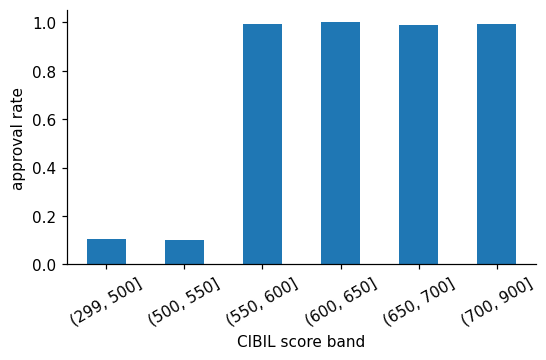

In [2]:
# Approval rate by credit score band: the dataset behaves like a rule
bands = pd.cut(d.cibil_score, [299,500,550,600,650,700,900])
rate = y.groupby(bands, observed=True).mean()
print(rate.round(3).to_string())
ax = rate.plot.bar(figsize=(5.5,3)); ax.set_ylabel('approval rate'); ax.set_xlabel('CIBIL score band'); plt.xticks(rotation=30); plt.show()

In [3]:
pre = ColumnTransformer([('c', OneHotEncoder(drop='if_binary'), cat), ('n', StandardScaler(), num)])
models = {'rule: cibil >= 550': None,
          'logistic regression': make_pipeline(pre, LogisticRegression(max_iter=1000)),
          'random forest': make_pipeline(pre, RandomForestClassifier(300, random_state=0, n_jobs=-1))}
cv = StratifiedKFold(5, shuffle=True, random_state=0); out = {}
for name, m in models.items():
    if m is None: p = (d.cibil_score>=550).astype(float).values
    else: p = cross_val_predict(m, X, y, cv=cv, method='predict_proba')[:,1]
    out[name] = p
    print(f'{name:<22} accuracy {accuracy_score(y, p>=0.5):.4f}  AUC {roc_auc_score(y, p):.4f}  Brier {brier_score_loss(y, p):.4f}')

rule: cibil >= 550     accuracy 0.9536  AUC 0.9611  Brier 0.0464


logistic regression    accuracy 0.9168  AUC 0.9681  Brier 0.0635


random forest          accuracy 0.9836  AUC 0.9981  Brier 0.0160


education                  -0.0006
self_employed              -0.0003
bank_asset_value            0.0001
luxury_assets_value         0.0005
no_of_dependents            0.0006
income_annum                0.0008
commercial_assets_value     0.0009
residential_assets_value    0.0021
loan_amount                 0.0046
loan_term                   0.0287
cibil_score                 0.4747


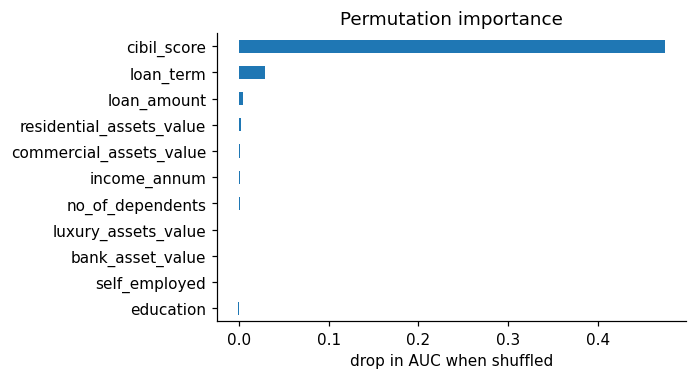

In [4]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=0, stratify=y)
rf = make_pipeline(pre, RandomForestClassifier(300, random_state=0, n_jobs=-1)).fit(Xtr, ytr)
pi = permutation_importance(rf, Xte, yte, n_repeats=10, random_state=0, scoring='roc_auc')
imp = pd.Series(pi.importances_mean, X.columns).sort_values()
print(imp.round(4).to_string()); imp.plot.barh(figsize=(5.5,3.4)); plt.xlabel('drop in AUC when shuffled'); plt.title('Permutation importance'); plt.show()

                pred  actual     n
(-0.001, 0.1]  0.024   0.000  1414
(0.1, 0.2]     0.147   0.000    41
(0.2, 0.3]     0.253   0.049    41
(0.3, 0.4]     0.347   0.061    49
(0.4, 0.5]     0.456   0.413    46
(0.5, 0.6]     0.548   0.729    59
(0.6, 0.7]     0.646   0.847    59
(0.7, 0.8]     0.753   0.889    63
(0.8, 0.9]     0.853   0.929    56
(0.9, 1.0]     0.985   0.996  2441


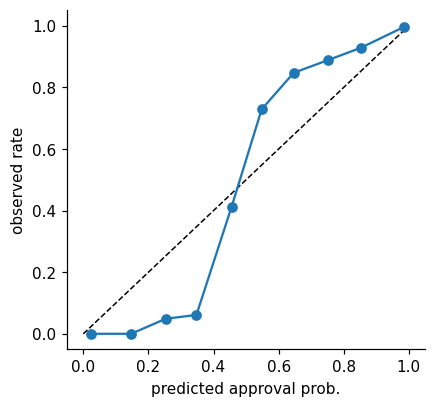

In [5]:
# Reliability (calibration) of the random forest probabilities
p = out['random forest']; bins = pd.cut(p, np.linspace(0,1,11), include_lowest=True)
cal = pd.DataFrame({'p':p,'y':y}).groupby(bins, observed=True).agg(pred=('p','mean'), actual=('y','mean'), n=('y','size'))
print(cal.round(3))
fig, ax = plt.subplots(figsize=(4.2,4)); ax.plot([0,1],[0,1],'k--',lw=1); ax.plot(cal.pred, cal.actual, 'o-'); ax.set_xlabel('predicted approval prob.'); ax.set_ylabel('observed rate'); plt.show()

Best threshold 0.65 | cost 200 | cost at 0.5: 254


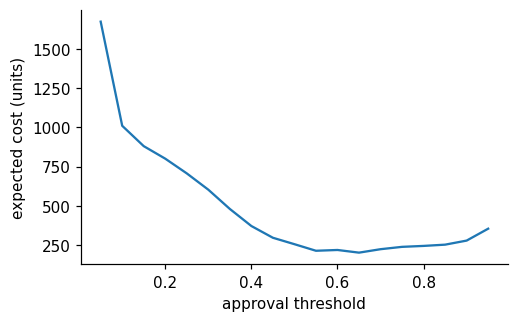

In [6]:
# Cost-sensitive threshold: approving a bad loan is assumed to cost 5x more than rejecting a good one
thr = np.linspace(.05, .95, 19); cost = []
for t in thr:
    approve = p >= t
    fp = (approve & (y==0)).sum(); fn = (~approve & (y==1)).sum(); cost.append(5*fp + fn)
print('Best threshold', round(thr[int(np.argmin(cost))],2), '| cost', int(min(cost)), '| cost at 0.5:', int(cost[9]))
plt.figure(figsize=(5,3)); plt.plot(thr, cost); plt.xlabel('approval threshold'); plt.ylabel('expected cost (units)'); plt.show()

In [7]:
# Group comparison (not a legal fairness audit): approval and error rates by education and self-employment
res = []
for g in ['education','self_employed']:
    for v, idx in d.groupby(g).groups.items():
        yy, pp = y.loc[idx], p[d.index.get_indexer(idx)]
        res.append({'group': f'{g}={v}', 'n': len(idx), 'actual approval': yy.mean(), 'predicted approval': (pp>=.5).mean(), 'false-approval rate': ((pp>=.5)&(yy==0)).sum()/(yy==0).sum(), 'false-rejection rate': ((pp<.5)&(yy==1)).sum()/(yy==1).sum()})
print(pd.DataFrame(res).round(3).to_string(index=False))

                 group    n  actual approval  predicted approval  false-approval rate  false-rejection rate
    education=Graduate 2144            0.625               0.631                0.031                 0.009
education=Not Graduate 2125            0.620               0.624                0.026                 0.009
      self_employed=No 2119            0.622               0.627                0.031                 0.011
     self_employed=Yes 2150            0.622               0.628                0.026                 0.007


## Results
See the outputs above: one-rule baseline vs logistic regression vs random forest under cross-validation, permutation importance, calibration, the cost-optimal threshold and group-level approval and error rates.

## Conclusions
1. **The dataset is almost a one-variable rule.** Applications with a CIBIL score above 550 are approved 99% to 100% of the time and those at or below 550 only about 10% of the time. A rule "approve if CIBIL >= 550" alone reaches 95.4% accuracy, so the 96% to 98% of the random forest is only a few points above a trivial baseline.
2. **The forest does add something, but little and mostly from the credit score.** With stratified 5-fold CV the random forest reaches 98.4% accuracy and 0.998 AUC against 91.7% and 0.968 for logistic regression. Permutation importance shows that the credit score explains almost everything (0.475 drop in AUC when shuffled), followed at a distance by loan term (0.029); income, assets, education and self-employment are close to zero. The earlier notebook's 96.25% used a sequential split, which is a harder (and more realistic) test than random folds.
3. **Probabilities are usable but under-confident in the middle.** In the 0.5 to 0.9 range the observed approval rate is higher than predicted (for example 0.729 observed vs 0.548 predicted in the 0.5 to 0.6 bin), and in the 0.1 to 0.4 range it is lower; the extreme bins are accurate. Calibrating the scores (isotonic or Platt) would improve decisions that rely on the probability rather than on the 0.5 cut.
4. **The threshold should follow the cost.** If a bad approval costs five times a missed good loan, the best threshold is 0.65 (cost 200) instead of 0.5 (cost 254), a 21% reduction. The 5x ratio is an assumption; a lender should replace it with its own loss data.
5. **No sign of group disparity on the variables checked.** Approval rates and false-approval and false-rejection rates are within about one percentage point between graduates and non-graduates and between self-employed and not (for example false approvals of 3.1% vs 2.6%). Education and self-employment have almost no importance, so this is expected; it is a basic check, not a fairness audit.
6. **Limits.** The data looks synthetic or heavily simplified (a near-deterministic rule is unusual in real credit data), there is no time dimension, and the dataset has no protected attributes such as age or gender, so fairness cannot be tested properly.

**Takeaway for the interview:** high accuracy is not a result until it is compared with a simple baseline. Here the baseline was a one-line rule, which changes how the model should be described and where the remaining effort (calibration and cost-based thresholds) should go.